# Redes Neuronales V — Notebook 02
## Red neuronal siamesa con Triplet Loss (TensorFlow + Keras)

**Idea.** Una red siamesa no clasifica personas: aprende una función $f(x)$ que convierte cada rostro en un **embedding** (vector de norma 1) tal que los rostros de la misma persona quedan cerca y los de personas distintas quedan lejos. Reconocer es entonces **comparar distancias**, por lo que se pueden añadir personas nuevas sin reentrenar (one-shot / few-shot).

```
  ancla ─────┐
  positivo ──┼──►  encoder f(·)  (MISMOS pesos en las 3 ramas)  ──► f(a), f(p), f(n)
  negativo ──┘                                                     │
                        d(a,p) = ||f(a) − f(p)||²   d(a,n) = ||f(a) − f(n)||²
                        L = max( d(a,p) − d(a,n) + α , 0 )        (Triplet Loss)
```

Se entrenan y comparan dos encoders dentro de la misma arquitectura siamesa:

| Encoder | Descripción | Parámetros entrenables |
|---|---|---|
| **A. FaceNet + cabeza siamesa** (transfer learning) | FaceNet (Inception-ResNet v1) pre-entrenado y congelado produce un vector de 128-d; una cabeza residual entrenable lo ajusta con Triplet Loss sobre nuestro dataset | ≈ 66 mil |
| **B. CNN desde cero** (línea base) | 4 bloques Conv-BN-ReLU-MaxPool + Dense(64) + normalización L2, entrenada sólo con nuestras fotos | ≈ 0.25 M |

Las identidades reservadas como **no vistas** no participan en ningún entrenamiento.

In [ ]:
# En Google Colab: instalar dependencias (una vez por sesión)
!pip install -q deepface tf-keras mtcnn

In [1]:
import os, sys, json, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
import tf_keras as keras
from sklearn.decomposition import PCA

SEED = 42
PUBLICAR_ROSTROS = True    # base pública ORL; con fotos propias usar False
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)
os.makedirs("modelos", exist_ok=True); os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
from __future__ import annotations
"""Preprocesamiento de imágenes faciales: detección, alineación, recorte, control de calidad y aumentos.

Flujo por imagen:
    leer (EXIF) -> RGB -> detectar rostro (MTCNN) -> alinear por los ojos -> recortar con margen
    -> redimensionar a 160x160 -> [estandarizar al pasar por el encoder]
"""

import os
from dataclasses import dataclass, field

import cv2
import numpy as np
from PIL import Image, ImageOps

IMG_SIZE = 160                      # entrada de FaceNet
VALID_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".pgm")


@dataclass
class FaceRecord:
    """Resultado del preprocesamiento de una foto."""
    person: str
    path: str
    face: np.ndarray | None = None            # rostro alineado 160x160x3 uint8
    confidence: float = 0.0
    n_faces: int = 0
    blur: float = 0.0                          # varianza del Laplaciano (nitidez)
    brightness: float = 0.0
    face_px: int = 0                           # ancho de la caja del rostro en la foto original
    status: str = "ok"
    notes: list = field(default_factory=list)


def read_image(path: str, max_side: int = 1024) -> np.ndarray:
    """Lee la imagen respetando la orientación EXIF del móvil y la reduce si es muy grande."""
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    if max(img.size) > max_side:
        img.thumbnail((max_side, max_side), Image.LANCZOS)
    return np.asarray(img)


def align_face(img: np.ndarray, left_eye, right_eye) -> tuple[np.ndarray, np.ndarray]:
    """Rota la imagen para que la línea entre los ojos quede horizontal. Devuelve imagen y matriz."""
    dy, dx = right_eye[1] - left_eye[1], right_eye[0] - left_eye[0]
    angle = np.degrees(np.arctan2(dy, dx))
    center = ((left_eye[0] + right_eye[0]) / 2.0, (left_eye[1] + right_eye[1]) / 2.0)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)
    return rotated, M


def crop_square(img: np.ndarray, box, margin: float = 0.2, size: int = IMG_SIZE) -> np.ndarray:
    """Recorte cuadrado centrado en la caja del rostro con un margen relativo; redimensiona a size x size."""
    x, y, w, h = box
    cx, cy, side = x + w / 2, y + h / 2, max(w, h) * (1 + margin)
    x1, y1 = int(round(cx - side / 2)), int(round(cy - side / 2))
    x2, y2 = x1 + int(round(side)), y1 + int(round(side))
    pad = max(0, -x1, -y1, x2 - img.shape[1], y2 - img.shape[0])
    if pad:
        img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_REFLECT)
        x1, y1, x2, y2 = x1 + pad, y1 + pad, x2 + pad, y2 + pad
    return cv2.resize(img[y1:y2, x1:x2], (size, size), interpolation=cv2.INTER_AREA)


class FacePreprocessor:
    """Detecta (MTCNN), alinea y recorta rostros; calcula métricas de calidad."""

    def __init__(self, min_confidence: float = 0.90, margin: float = 0.2, min_face_px: int = 60):
        from mtcnn import MTCNN                       # import diferido: es pesado
        self.detector = MTCNN()
        self.min_confidence, self.margin, self.min_face_px = min_confidence, margin, min_face_px

    def detect(self, img):
        dets = [d for d in self.detector.detect_faces(img) if d["confidence"] >= self.min_confidence]
        return sorted(dets, key=lambda d: d["box"][2] * d["box"][3], reverse=True)   # mayor primero

    def process(self, path: str, person: str) -> FaceRecord:
        rec = FaceRecord(person=person, path=path)
        img = read_image(path)
        dets = self.detect(img)
        rec.n_faces = len(dets)
        if not dets:
            rec.status = "sin_rostro"
            return rec
        if len(dets) > 1:
            rec.notes.append(f"{len(dets)} rostros: se usa el más grande")
        d = dets[0]
        rec.confidence, rec.face_px = float(d["confidence"]), int(d["box"][2])
        kp = d["keypoints"]
        # en MTCNN 'left_eye' es el ojo que aparece a la izquierda de la imagen
        rotated, M = align_face(img, kp["left_eye"], kp["right_eye"])
        x, y, w, h = d["box"]
        cx, cy = M @ np.array([x + w / 2, y + h / 2, 1.0])        # centro de la caja tras la rotación
        rec.face = crop_square(rotated, (cx - w / 2, cy - h / 2, w, h), self.margin)
        gray = cv2.cvtColor(rec.face, cv2.COLOR_RGB2GRAY)
        rec.blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        rec.brightness = float(gray.mean())
        if rec.face_px < self.min_face_px:
            rec.notes.append("rostro pequeño")
        return rec


def natkey(s: str):
    """Orden natural: s2 antes que s10."""
    import re
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]


def list_dataset(root: str) -> dict[str, list[str]]:
    """{persona: [rutas]} a partir de root/<persona>/<imagen>."""
    people = {}
    for person in sorted(os.listdir(root), key=natkey):
        pdir = os.path.join(root, person)
        if os.path.isdir(pdir) and not person.startswith((".", "_")):
            files = sorted((os.path.join(pdir, f) for f in os.listdir(pdir) if f.lower().endswith(VALID_EXT)), key=natkey)
            if files:
                people[person] = files
    return people


def standardize(faces: np.ndarray) -> np.ndarray:
    """Estandarización por imagen (prewhitening de FaceNet): media 0 y desviación 1 en cada rostro."""
    x = faces.astype("float32")
    mean = x.mean(axis=(1, 2, 3), keepdims=True)
    std = np.maximum(x.std(axis=(1, 2, 3), keepdims=True), 1.0 / np.sqrt(x[0].size))
    return (x - mean) / std


def augment(face: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Aumento de datos fotométrico y geométrico leve (sólo para entrenamiento)."""
    img = face.astype("float32")
    if rng.random() < 0.5:
        img = img[:, ::-1]                                               # espejo horizontal
    angle, scale = rng.uniform(-10, 10), rng.uniform(0.95, 1.08)         # rotación y zoom leves
    tx, ty = rng.uniform(-6, 6, size=2)
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, scale); M[:, 2] += (tx, ty)
    img = cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT)
    img = img * rng.uniform(0.75, 1.25) + rng.uniform(-25, 25)           # contraste y brillo
    if rng.random() < 0.2:
        img = cv2.GaussianBlur(img, (3, 3), 0)
    return np.clip(img, 0, 255).astype("uint8")


def anonymize(face: np.ndarray, blocks: int = 8) -> np.ndarray:
    """Pixela un rostro para figuras públicas cuando no hay permiso de publicar la imagen."""
    small = cv2.resize(face, (blocks, blocks), interpolation=cv2.INTER_LINEAR)
    return cv2.resize(small, face.shape[:2][::-1], interpolation=cv2.INTER_NEAREST)

In [3]:
"""Red siamesa con Triplet Loss en TensorFlow/Keras (API tf_keras, compatible con FaceNet de deepface).

Componentes
-----------
* Encoders f(x) -> embedding de norma 1:
    - build_facenet_head:   cabeza residual entrenable sobre embeddings FaceNet pre-entrenados (transfer learning)
    - build_scratch_encoder: CNN pequeña entrenada desde cero (línea base)
* build_siamese_triplet: modelo siamés de 3 ramas (ancla, positivo, negativo) que COMPARTEN el encoder
* triplet_loss:  L = max(||f(a)-f(p)||² - ||f(a)-f(n)||² + margen, 0)
* mine_triplets: selección de tripletas semi-difíciles (FaceNet, Schroff et al., 2015)
"""

import numpy as np
import tensorflow as tf
import tf_keras as keras

MARGIN = 0.2


# ----------------------------------------------------------------------------- encoders
class L2Normalize(keras.layers.Layer):
    """Proyecta el embedding sobre la hiperesfera unitaria: ||f(x)||₂ = 1."""
    def call(self, x):
        return tf.math.l2_normalize(x, axis=-1)


def load_facenet():
    """FaceNet (Inception-ResNet v1, 128-d) pre-entrenado; pesos públicos distribuidos por deepface."""
    from deepface import DeepFace
    model = DeepFace.build_model("Facenet").model
    model.trainable = False
    return model


def build_facenet_head(in_dim: int = 128, emb_dim: int = 128, hidden: int = 256, dropout: float = 0.2):
    """Cabeza residual: f(x) = normalize(x + g(x)). g se inicializa en cero, así que al empezar
    el encoder reproduce exactamente FaceNet y el entrenamiento sólo aprende la corrección."""
    x_in = keras.Input(shape=(in_dim,), name="facenet_emb")
    x_n = L2Normalize(name="l2_entrada")(x_in)                 # FaceNet entrega vectores sin normalizar
    h = keras.layers.Dense(hidden, activation="relu", name="head_dense")(x_n)
    h = keras.layers.Dropout(dropout)(h)
    delta = keras.layers.Dense(emb_dim, kernel_initializer="zeros", name="head_delta")(h)
    out = L2Normalize(name="l2norm")(keras.layers.Add()([x_n, delta]) if in_dim == emb_dim else delta)
    return keras.Model(x_in, out, name="encoder_facenet_head")


def build_scratch_encoder(input_shape=(96, 96, 3), emb_dim: int = 64):
    """CNN compacta entrenada desde cero (sin conocimiento previo de rostros)."""
    x_in = keras.Input(shape=input_shape, name="rostro")
    x = x_in
    for filters in (32, 64, 128, 128):
        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ReLU()(x)
        x = keras.layers.MaxPooling2D()(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.3)(x)
    x = keras.layers.Dense(emb_dim)(x)
    return keras.Model(x_in, L2Normalize(name="l2norm")(x), name="encoder_cnn_desde_cero")


# ----------------------------------------------------------------------------- red siamesa
class TripletDistances(keras.layers.Layer):
    """Calcula d(a,p) y d(a,n) como distancias euclidianas al cuadrado."""
    def call(self, inputs):
        a, p, n = inputs
        return tf.stack([tf.reduce_sum(tf.square(a - p), -1), tf.reduce_sum(tf.square(a - n), -1)], axis=-1)


def triplet_loss(margin: float = MARGIN):
    """Triplet Loss: empuja d(a,p) por debajo de d(a,n) con al menos 'margin' de separación."""
    def loss(_, d):                                   # y_true no se usa: la supervisión está en la tripleta
        return tf.reduce_mean(tf.maximum(d[:, 0] - d[:, 1] + margin, 0.0))
    loss.__name__ = "triplet_loss"
    return loss


def triplet_accuracy(_, d):
    """Fracción de tripletas bien ordenadas: d(a,p) < d(a,n)."""
    return tf.reduce_mean(tf.cast(d[:, 0] < d[:, 1], tf.float32))


def build_siamese_triplet(encoder, margin: float = MARGIN, lr: float = 1e-3):
    """Arquitectura siamesa de tres ramas con pesos compartidos (un único 'encoder')."""
    shape = encoder.input_shape[1:]
    a, p, n = (keras.Input(shape=shape, name=nm) for nm in ("ancla", "positivo", "negativo"))
    d = TripletDistances(name="distancias")([encoder(a), encoder(p), encoder(n)])
    model = keras.Model([a, p, n], d, name="red_siamesa_triplet")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=triplet_loss(margin), metrics=[triplet_accuracy])
    return model


# ----------------------------------------------------------------------------- minado de tripletas
def pairwise_sq_dist(e: np.ndarray) -> np.ndarray:
    sq = (e ** 2).sum(1)
    return np.maximum(sq[:, None] + sq[None, :] - 2 * e @ e.T, 0.0)


def mine_triplets(emb: np.ndarray, labels: np.ndarray, margin: float = MARGIN, rng=None, max_per_anchor: int = 4):
    """Para cada par (ancla, positivo) elige un negativo semi-difícil:
    d(a,p) < d(a,n) < d(a,p) + margen. Si no existe, toma el negativo más cercano que no sea
    más cercano que el positivo; en último caso uno aleatorio."""
    rng = rng or np.random.default_rng(0)
    D = pairwise_sq_dist(emb)
    triplets, kinds = [], {"semi-difícil": 0, "difícil": 0, "aleatorio": 0}
    for a in range(len(labels)):
        pos = np.where((labels == labels[a]) & (np.arange(len(labels)) != a))[0]
        neg = np.where(labels != labels[a])[0]
        if not len(pos) or not len(neg):
            continue
        for p in rng.permutation(pos)[:max_per_anchor]:
            dap, dan = D[a, p], D[a, neg]
            semi = neg[(dan > dap) & (dan < dap + margin)]
            if len(semi):
                n = rng.choice(semi); kinds["semi-difícil"] += 1
            elif (dan > dap).any():
                cand = neg[dan > dap]; n = cand[np.argmin(D[a, cand])]; kinds["difícil"] += 1
            else:
                n = rng.choice(neg); kinds["aleatorio"] += 1
            triplets.append((a, p, n))
    return np.array(triplets), kinds


# ----------------------------------------------------------------------------- utilidades de evaluación
def embed(encoder, x, batch: int = 64) -> np.ndarray:
    return encoder.predict(x, batch_size=batch, verbose=0)


def pair_scores(emb: np.ndarray, labels: np.ndarray):
    """Distancias de todos los pares (i<j) y si son de la misma persona (genuino) o no (impostor)."""
    D = pairwise_sq_dist(emb)
    iu = np.triu_indices(len(labels), k=1)
    return D[iu], (labels[iu[0]] == labels[iu[1]]).astype(int)


def verification_metrics(dist: np.ndarray, same: np.ndarray, threshold: float | None = None):
    """ROC-AUC, EER y exactitud de verificación con un umbral (si no se da, el que iguala FAR y FRR)."""
    from sklearn.metrics import roc_auc_score, roc_curve
    score = -dist                                     # menor distancia = más parecido
    auc = roc_auc_score(same, score)
    fpr, tpr, thr = roc_curve(same, score)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    eer, eer_thr = (fpr[i] + fnr[i]) / 2, -thr[i]
    t = eer_thr if threshold is None else threshold
    pred = (dist <= t).astype(int)
    far = ((pred == 1) & (same == 0)).sum() / max((same == 0).sum(), 1)
    frr = ((pred == 0) & (same == 1)).sum() / max((same == 1).sum(), 1)
    return {"AUC": auc, "EER": eer, "umbral_EER": eer_thr, "umbral": t, "exactitud": (pred == same).mean(),
            "FAR": far, "FRR": frr, "roc": (fpr, tpr)}

## 1. Datos preprocesados (Notebook 01)

In [4]:
d = np.load("procesado/rostros.npz", allow_pickle=False)
faces, labels_txt, subset = d["faces"], d["labels"], d["subset"]
NO_VISTAS = [n for n in str(d["no_vista"]).split(",") if n]
names = sorted(set(labels_txt), key=natkey)
lab = np.array([names.index(n) for n in labels_txt])
tr = subset == "train"
print(f"{len(names)} identidades | {len(NO_VISTAS)} no vistas: {NO_VISTAS}")
print("Imágenes por conjunto:", pd.Series(subset).value_counts().to_dict())

40 identidades | 10 no vistas: ['s3', 's4', 's8', 's15', 's16', 's22', 's25', 's27', 's31', 's40']
Imágenes por conjunto: {'train': 179, 'test': 120, 'no_vista': 100}


## 2. Encoder A — FaceNet pre-entrenado + cabeza siamesa
FaceNet (Schroff, Kalenichenko y Philbin, 2015) ya fue entrenado con Triplet Loss sobre millones de rostros; sus pesos públicos se cargan con `deepface`. Se **congela** (22.8 M parámetros) y se entrena sólo la cabeza residual:

$$f(x) = \frac{\hat{e} + g(\hat{e})}{\lVert \hat{e} + g(\hat{e}) \rVert_2},\qquad \hat{e} = \frac{\mathrm{FaceNet}(x)}{\lVert \mathrm{FaceNet}(x)\rVert_2}$$

$g$ (Dense 256 ReLU → Dropout → Dense 128) se inicializa en cero, por lo que el entrenamiento parte exactamente de FaceNet y sólo aprende la corrección específica de nuestro dataset. Como FaceNet está congelado, sus embeddings se **pre-calculan** una vez para cada imagen y para `N_AUG` versiones aumentadas, lo que hace el entrenamiento viable en CPU.

In [5]:
facenet = load_facenet()
print(f"FaceNet: entrada {facenet.input_shape}, salida {facenet.output_shape}, {facenet.count_params():,} parámetros (congelados)")

N_AUG = 15
rng = np.random.default_rng(SEED)
tr_idx = np.where(tr)[0]
aug_faces = [faces[i] for i in tr_idx] + [augment(faces[i], rng) for _ in range(N_AUG) for i in tr_idx]
aug_lab = np.concatenate([lab[tr_idx]] * (N_AUG + 1))
t0 = time.time()
E_train = facenet.predict(standardize(np.stack(aug_faces)), batch_size=32, verbose=0)
E_all = facenet.predict(standardize(faces), batch_size=32, verbose=0)
print(f"Embeddings FaceNet: train+aumentos {E_train.shape}, todas las imágenes {E_all.shape} ({time.time() - t0:.0f} s)")

FaceNet: entrada (None, 160, 160, 3), salida (None, 128), 22,808,144 parámetros (congelados)


Embeddings FaceNet: train+aumentos (2864, 128), todas las imágenes (399, 128) (91 s)


In [6]:
head = build_facenet_head()
siamese_A = build_siamese_triplet(head, margin=MARGIN, lr=1e-3)
siamese_A.summary(line_length=100)

Model: "red_siamesa_triplet"


____________________________________________________________________________________________________


 Layer (type)                 Output Shape                  Param #   Connected to                  


 ancla (InputLayer)           [(None, 128)]                 0         []                            


 positivo (InputLayer)        [(None, 128)]                 0         []                            


 negativo (InputLayer)        [(None, 128)]                 0         []                            


... (6 outputs left out)

Total params: 65920 (257.50 KB)


Trainable params: 65920 (257.50 KB)


Non-trainable params: 0 (0.00 Byte)


____________________________________________________________________________________________________


### Entrenamiento con minado de tripletas semi-difíciles
En cada época se recalculan los embeddings con el encoder actual y, para cada par (ancla, positivo), se elige un negativo **semi-difícil**: más lejano que el positivo pero dentro del margen α. Las tripletas fáciles (pérdida 0) no aportan gradiente y las más difíciles pueden desestabilizar el entrenamiento (Schroff et al., 2015).

In [7]:
def train_siamese(siamese, encoder, X, y, epochs, rng, batch=64, inputs_fn=None, log_every=5):
    """Entrenamiento por épocas: embed -> minar tripletas -> una pasada en mini-lotes sobre las tripletas.
    Los lotes se arman por índices (train_on_batch) para no copiar en memoria todas las tripletas."""
    hist = {"loss": [], "triplet_accuracy": [], "semi-difícil": [], "difícil": [], "aleatorio": []}
    for ep in range(1, epochs + 1):
        Xe = inputs_fn(X, rng) if inputs_fn else X
        emb = encoder.predict(Xe, batch_size=128, verbose=0)
        T, kinds = mine_triplets(emb, y, MARGIN, rng)
        T = T[rng.permutation(len(T))]
        losses, accs, sizes = [], [], []
        for s in range(0, len(T), batch):
            b = T[s:s + batch]
            l, a = siamese.train_on_batch([Xe[b[:, 0]], Xe[b[:, 1]], Xe[b[:, 2]]], np.zeros(len(b)))
            losses.append(l); accs.append(a); sizes.append(len(b))
        hist["loss"].append(float(np.average(losses, weights=sizes)))
        hist["triplet_accuracy"].append(float(np.average(accs, weights=sizes)))
        for k, v in kinds.items(): hist[k].append(v)
        if ep % log_every == 0 or ep == 1:
            print(f"época {ep:3d} | tripletas {len(T):5d} (semi-difíciles {kinds['semi-difícil']:4d}) | "
                  f"pérdida {hist['loss'][-1]:.4f} | tripletas correctas {hist['triplet_accuracy'][-1]:.3f}")
    return hist

t0 = time.time()
hist_A = train_siamese(siamese_A, head, E_train, aug_lab, epochs=40, rng=np.random.default_rng(SEED))
time_A = time.time() - t0
print(f"Tiempo de entrenamiento: {time_A:.1f} s")
head.save("modelos/encoder_facenet_head.keras")

época   1 | tripletas 11456 (semi-difíciles  318) | pérdida 0.0000 | tripletas correctas 1.000


época   5 | tripletas 11456 (semi-difíciles    1) | pérdida 0.0000 | tripletas correctas 1.000


época  10 | tripletas 11456 (semi-difíciles    0) | pérdida 0.0000 | tripletas correctas 1.000


época  15 | tripletas 11456 (semi-difíciles    0) | pérdida 0.0000 | tripletas correctas 1.000


época  20 | tripletas 11456 (semi-difíciles    0) | pérdida 0.0000 | tripletas correctas 1.000


época  25 | tripletas 11456 (semi-difíciles    0) | pérdida 0.0000 | tripletas correctas 1.000


época  30 | tripletas 11456 (semi-difíciles    0) | pérdida 0.0000 | tripletas correctas 1.000


época  35 | tripletas 11456 (semi-difíciles    0) | pérdida 0.0000 | tripletas correctas 1.000


época  40 | tripletas 11456 (semi-difíciles    0) | pérdida 0.0000 | tripletas correctas 1.000
Tiempo de entrenamiento: 84.3 s


## 3. Encoder B — CNN entrenada desde cero (línea base)
Misma arquitectura siamesa y misma Triplet Loss, pero el encoder no tiene conocimiento previo de rostros. Entrada 96×96 escalada a [0, 1]; en cada época se generan 2 versiones aumentadas nuevas de las fotos de entrenamiento.

In [8]:
SIZE_B = 96
def to_b(x): return np.stack([cv2.resize(f, (SIZE_B, SIZE_B), interpolation=cv2.INTER_AREA) for f in x]).astype("float32") / 255.0
X_b_tr = faces[tr_idx]; y_b_tr = lab[tr_idx]
def aug_inputs(X, rng, copies=2):
    return to_b(np.stack([augment(f, rng) for _ in range(copies) for f in X]))
y_b_rep = np.concatenate([y_b_tr] * 2)

scratch = build_scratch_encoder((SIZE_B, SIZE_B, 3), emb_dim=64)
siamese_B = build_siamese_triplet(scratch, margin=MARGIN, lr=1e-3)
print(f"Encoder B: {scratch.count_params():,} parámetros")
t0 = time.time()
hist_B = train_siamese(siamese_B, scratch, X_b_tr, y_b_rep, epochs=40, rng=np.random.default_rng(SEED), batch=32,
                       inputs_fn=aug_inputs, log_every=10)
time_B = time.time() - t0
print(f"Tiempo de entrenamiento: {time_B:.1f} s")
scratch.save("modelos/encoder_cnn_desde_cero.keras")

Encoder B: 250,144 parámetros


época   1 | tripletas  1432 (semi-difíciles 1429) | pérdida 0.1355 | tripletas correctas 0.707


época  10 | tripletas  1432 (semi-difíciles 1432) | pérdida 0.0728 | tripletas correctas 0.855


época  20 | tripletas  1432 (semi-difíciles 1419) | pérdida 0.0840 | tripletas correctas 0.830


época  30 | tripletas  1432 (semi-difíciles 1384) | pérdida 0.0521 | tripletas correctas 0.891


época  40 | tripletas  1432 (semi-difíciles 1007) | pérdida 0.0663 | tripletas correctas 0.863
Tiempo de entrenamiento: 1018.8 s


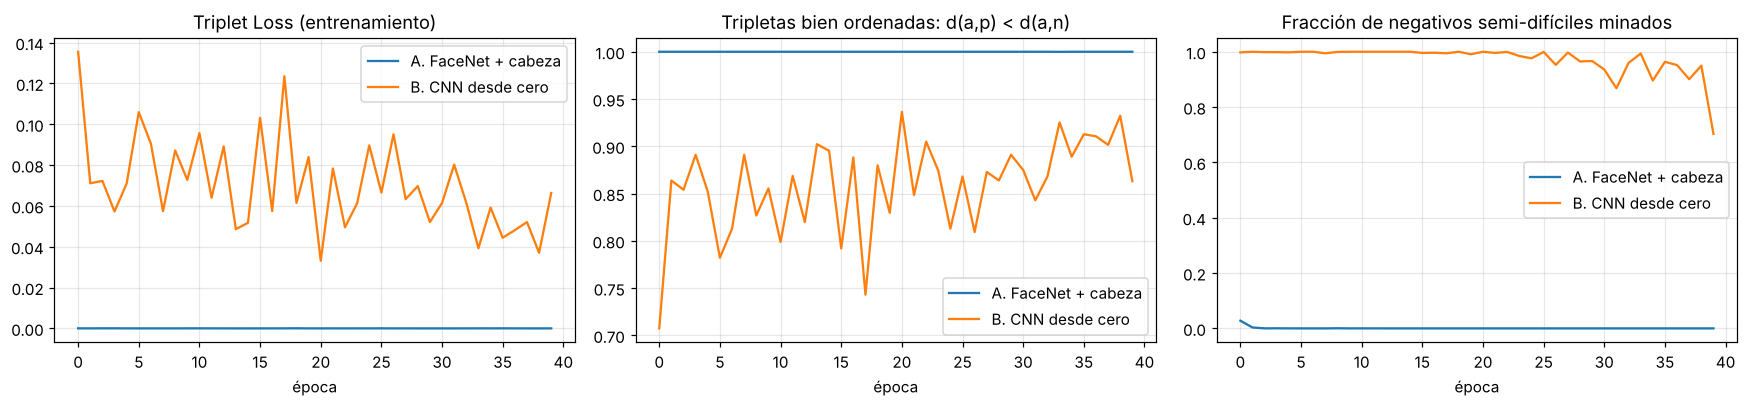

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for name, h in [("A. FaceNet + cabeza", hist_A), ("B. CNN desde cero", hist_B)]:
    ax[0].plot(h["loss"], label=name); ax[1].plot(h["triplet_accuracy"], label=name)
    tot = np.array(h["semi-difícil"]) + np.array(h["difícil"]) + np.array(h["aleatorio"])
    ax[2].plot(np.array(h["semi-difícil"]) / tot, label=name)
ax[0].set_title("Triplet Loss (entrenamiento)"); ax[1].set_title("Tripletas bien ordenadas: d(a,p) < d(a,n)")
ax[2].set_title("Fracción de negativos semi-difíciles minados")
for a in ax: a.set_xlabel("época"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/02_entrenamiento.png", bbox_inches="tight"); plt.show()

## 4. Espacio de embeddings
Embeddings de las **identidades no vistas** (ninguna participó en el entrenamiento) proyectados a 2-D con PCA. Se comparan FaceNet sin ajustar, FaceNet + cabeza siamesa y la CNN desde cero: un buen encoder agrupa las fotos de cada persona aunque nunca la haya visto.

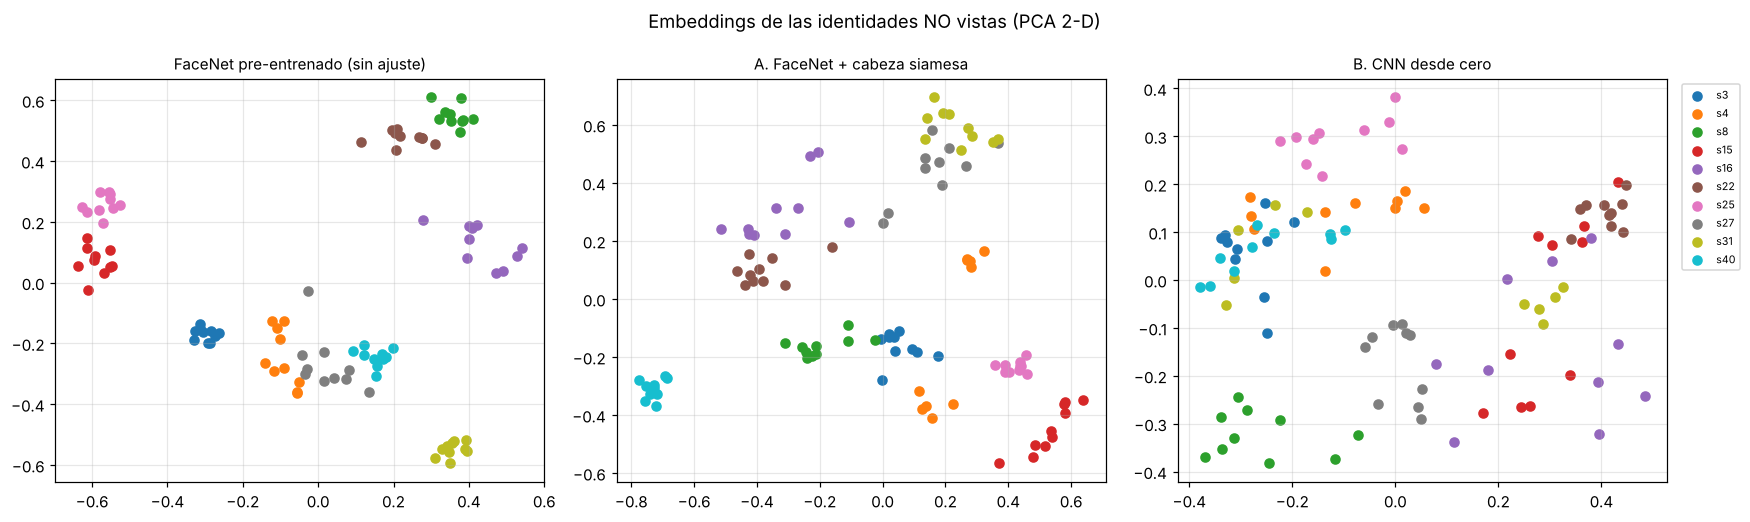

In [10]:
emb = {"FaceNet pre-entrenado (sin ajuste)": E_all / np.linalg.norm(E_all, axis=1, keepdims=True),
       "A. FaceNet + cabeza siamesa": head.predict(E_all, verbose=0),
       "B. CNN desde cero": scratch.predict(to_b(faces), verbose=0)}
np.savez_compressed("procesado/embeddings.npz", **{k.split(" ")[0].replace(".", ""): v for k, v in emb.items()})
ev = subset != "train"
nvm = subset == "no_vista"
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for a, (name, e) in zip(axes, emb.items()):
    p2 = PCA(2, random_state=SEED).fit_transform(e[nvm])
    for k, n in enumerate(NO_VISTAS):
        m = labels_txt[nvm] == n
        a.scatter(p2[m, 0], p2[m, 1], s=35, label=n, color=plt.cm.tab10(k % 10))
    a.set_title(name, fontsize=10); a.grid(alpha=0.3)
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Embeddings de las identidades NO vistas (PCA 2-D)")
plt.tight_layout(); plt.savefig("figures/02_embeddings_pca.png", bbox_inches="tight"); plt.show()

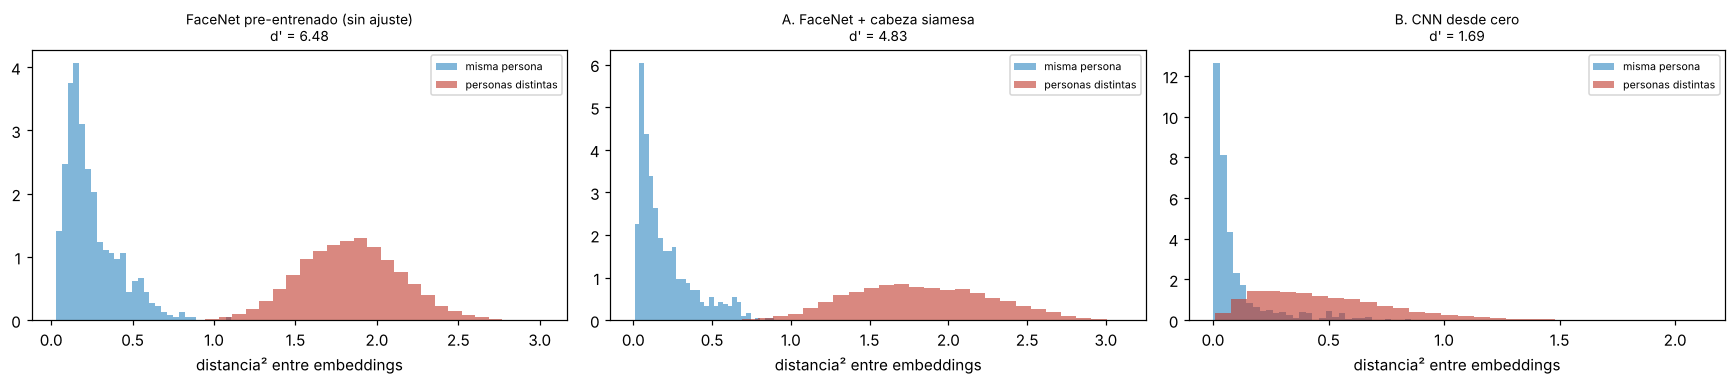

,d_genuina_media,d_impostor_media,d_prima
FaceNet pre-entrenado (sin ajuste),0.2467,1.8355,6.4834
A. FaceNet + cabeza siamesa,0.1997,1.8202,4.8294
B. CNN desde cero,0.0955,0.4859,1.6922


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=False)
sep = {}
for a, (name, e) in zip(axes, emb.items()):
    dist, same = pair_scores(e[ev], lab[ev])
    a.hist(dist[same == 1], bins=30, alpha=0.6, density=True, label="misma persona", color="#2e86c1")
    a.hist(dist[same == 0], bins=30, alpha=0.6, density=True, label="personas distintas", color="#c0392b")
    sep[name] = {"d_genuina_media": float(dist[same == 1].mean()), "d_impostor_media": float(dist[same == 0].mean()),
                 "d_prima": float((dist[same == 0].mean() - dist[same == 1].mean()) / np.sqrt(0.5 * (dist[same == 0].var() + dist[same == 1].var())))}
    a.set_title(f"{name}\nd' = {sep[name]['d_prima']:.2f}", fontsize=9); a.set_xlabel("distancia² entre embeddings"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("figures/02_distancias.png", bbox_inches="tight"); plt.show()
pd.DataFrame(sep).T.round(4)

In [12]:
res = {"N_AUG": N_AUG, "margen": MARGIN, "tripletas_por_epoca_A": int(sum(hist_A[k][-1] for k in ("semi-difícil", "difícil", "aleatorio"))),
       "A": {"epocas": len(hist_A["loss"]), "loss_inicial": hist_A["loss"][0], "loss_final": hist_A["loss"][-1],
             "tripletas_ok_final": hist_A["triplet_accuracy"][-1], "tiempo_s": round(time_A, 1), "params_entrenables": head.count_params()},
       "B": {"epocas": len(hist_B["loss"]), "loss_inicial": hist_B["loss"][0], "loss_final": hist_B["loss"][-1],
             "tripletas_ok_final": hist_B["triplet_accuracy"][-1], "tiempo_s": round(time_B, 1), "params_entrenables": scratch.count_params()},
       "separacion": sep, "facenet_params": facenet.count_params()}
json.dump(res, open("results/02_entrenamiento.json", "w"), indent=2, ensure_ascii=False, default=float)

## 5. Conclusiones
* **Encoder A (FaceNet + cabeza).** FaceNet ya separa casi perfectamente a estas personas: en la primera época sólo 318 de 11 456 tripletas fueron semi-difíciles y desde la época 5 no quedó ninguna, por lo que la Triplet Loss se hizo 0 y la cabeza dejó de aprender. Ese breve ajuste compactó las identidades de entrenamiento pero **redujo la separabilidad en identidades no vistas** (d′ de 6.48 a 4.83): con sólo 30 personas la cabeza se sobreajusta.
* **Encoder B (CNN desde cero).** La Triplet Loss sí guía el aprendizaje: la fracción de tripletas bien ordenadas sube de 0.71 a 0.86–0.89 y siempre hay negativos semi-difíciles disponibles (la tarea sigue siendo difícil). En identidades no vistas logra d′ = 1.69: aprendió una métrica facial útil a partir de sólo 179 fotos, aunque muy lejos de FaceNet.
* **Costo:** A entrenó en 84 s (FaceNet congelado y embeddings pre-calculados); B necesitó 1 019 s en CPU.
* Conclusión: con pocos datos, el conocimiento previo de un modelo entrenado con millones de rostros pesa mucho más que el ajuste local; ajustar una cabeza con pocas identidades debe validarse, porque puede empeorar la generalización.